In [1]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import csv
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
import os
import re
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

In [2]:
db_folder = '../Photometric_DB'
total_cores = os.cpu_count() - 2

In [3]:
session_paths = []

for id in os.listdir(db_folder):
    if id.isdigit():
        id_path = os.path.join(db_folder, id)
        for session in os.listdir(id_path):
            session_path = os.path.join(id_path, session)
            if os.path.isdir(session_path):
                session_paths.append(session_path)

# 1. Hiểu phân bổ các task trong metadata.csv của dữ liệu raw

## Chuyển metadata_all.txt của daset gốc thành file csv

In [4]:
metadata_path = '../Photometric_DB/metadata_all.txt'
output_path = './multi/metadata.csv'

# id: Nhận diện danh tính (số id bằng số session)
# gender: Giới tính
# spectacles: Kính
# facial_hair: Râu
# pose: Tư thế
# quality: Chất lượng
# Occlusion: Mờ
# Emotion: Cảm xúc
header = [
    'id', 'session', 'Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Quality', 'Occlusion', 'Emotion'
]

processed_data = []

# 31 trường: Lấy col 1-2, 25-31 bỏ 32
with open(metadata_path, 'r') as f:
    lines = f.readlines()
    
    for line in lines:
        fields = line.strip().split(", ")
        
        # Làm sạch cột Emotion nếu có dấu ngoặc kép thừa hoặc dấu phẩy thừa
        if str(fields[30]).startswith('"') and str(fields[30]).endswith('"'):
            fields[30] = fields[30][1:-1]  # Loại bỏ dấu ngoặc kép thừa
        
        # Làm sạch dấu phẩy thừa trong Emotion
        if fields[30].endswith(','):
            fields[30] = fields[30][:-1]  # Loại bỏ dấu phẩy cuối chuỗi
        
        # Loại bỏ các thông tin về landmark (cột từ index 2 đến 21) và "other"
        filtered_fields = fields[:2] + fields[24:31]
        
        # Thêm vào processed_data
        processed_data.append(filtered_fields)

# Ghi dữ liệu đã làm sạch vào file CSV mới
with open(output_path, 'w', newline='') as csvfile:
    csv_writer = csv.writer(csvfile)
    # Ghi header và dữ liệu vào file CSV
    csv_writer.writerow(header)
    csv_writer.writerows(processed_data)

print("File đã được làm sạch và ghi lại vào:", output_path)

File đã được làm sạch và ghi lại vào: ./multi/metadata.csv


## Loại bỏ các session trong final_session_remove.txt

In [6]:
# 1. Đọc file metadata.csv đã chuyển đổi trước đó
metadata_df = pd.read_csv('./multi/metadata.csv')

# 2. Đọc file chứa danh sách các session cần loại bỏ
remove_file = 'final_session_remove.txt'
sessions_to_remove = set()

if os.path.exists(remove_file):
    with open(remove_file, 'r', encoding='utf-8') as f:
        for line in f:
            sessions_to_remove.add(line.strip())

# 3. Tạo lại cột 'session_path' trong metadata_df để khớp định dạng với file remove
# Giả sử cấu trúc đường dẫn trong Photometric_DB là: ../Photometric_DB/{id}/{session}
metadata_df['session_path'] = '../Photometric_DB/' + metadata_df['id'].astype(str) + '/' + metadata_df['session'].astype(str)

# 4. Lọc bỏ các session nằm trong danh sách cần xóa
# Giữ lại những dòng có session_path KHÔNG CÓ trong sessions_to_remove
filtered_metadata_df = metadata_df[~metadata_df['session_path'].isin(sessions_to_remove)].copy()

# 5. Xóa cột tạm 'session_path' trước khi lưu (nếu bạn muốn giữ nguyên 9 cột ban đầu)
filtered_metadata_df = filtered_metadata_df.drop(columns=['session_path'])

# 6. Lưu file CSV đã được làm sạch hoàn toàn
final_output_path = './multi/metadata_filtered.csv'
filtered_metadata_df.to_csv(final_output_path, index=False)

print(f"Ban đầu có: {len(metadata_df)} dòng.")
print(f"Đã loại bỏ: {len(metadata_df) - len(filtered_metadata_df)} dòng lỗi/bad pose.")
print(f"Dữ liệu sạch còn lại: {len(filtered_metadata_df)} dòng. Đã lưu tại: {final_output_path}")

Ban đầu có: 3159 dòng.
Đã loại bỏ: 103 dòng lỗi/bad pose.
Dữ liệu sạch còn lại: 3056 dòng. Đã lưu tại: ./multi/metadata_filtered.csv


## Trực quan hóa dữ liệu

In [7]:
# Đọc file CSV và đếm số lượng các loại giá trị duy nhất cho các cột trừ 'id' và 'session'
def count_unique_values(csv_path, headers_to_exclude):
    unique_values_by_column = {header: set() for header in headers_to_exclude}

    with open(csv_path, 'r') as csvfile:
        csv_reader = csv.reader(csvfile)
        headers = next(csv_reader)  # Đọc header
        
        # Lấy chỉ số của các header cần đếm
        for row in csv_reader:
            for header, value in zip(headers, row):
                if header in headers_to_exclude:
                    unique_values_by_column[header].add(value)  # Thêm giá trị duy nhất vào set

    return unique_values_by_column

# Hiển thị số lượng các loại (unique values) có trong từng cột
def display_unique_values(unique_values_by_column):
    for column, unique_values in unique_values_by_column.items():
        print(f"Unique values in {column}: {sorted(unique_values)}")
        print(f"Total number of unique values in {column}: {len(unique_values)}\n")

# Đường dẫn tới file CSV
csv_path = './multi/metadata.csv'

# Các header cần xử lý (trừ 'id' và 'session')
headers_to_exclude = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Quality', 'Occlusion', 'Emotion']

# Đếm các loại giá trị duy nhất trong từng cột
unique_values_by_column = count_unique_values(csv_path, headers_to_exclude)

# Hiển thị các loại và số lượng có trong từng cột
display_unique_values(unique_values_by_column)

Unique values in Gender: ['female', 'male']
Total number of unique values in Gender: 2

Unique values in Spectacles: ['no', 'yes']
Total number of unique values in Spectacles: 2

Unique values in Facial_Hair: ['beard', 'both', 'moustache', 'none', 'stubble']
Total number of unique values in Facial_Hair: 5

Unique values in Pose: ['1', '2', '3', '4', '5']
Total number of unique values in Pose: 5

Unique values in Quality: ['blur', 'dark', 'ok']
Total number of unique values in Quality: 3

Unique values in Occlusion: ['', '-hair', '-hand', '-hand-other', '-mobile', '-other']
Total number of unique values in Occlusion: 6

Unique values in Emotion: ['blankstare', 'emoOther', 'negative', 'positive']
Total number of unique values in Emotion: 4



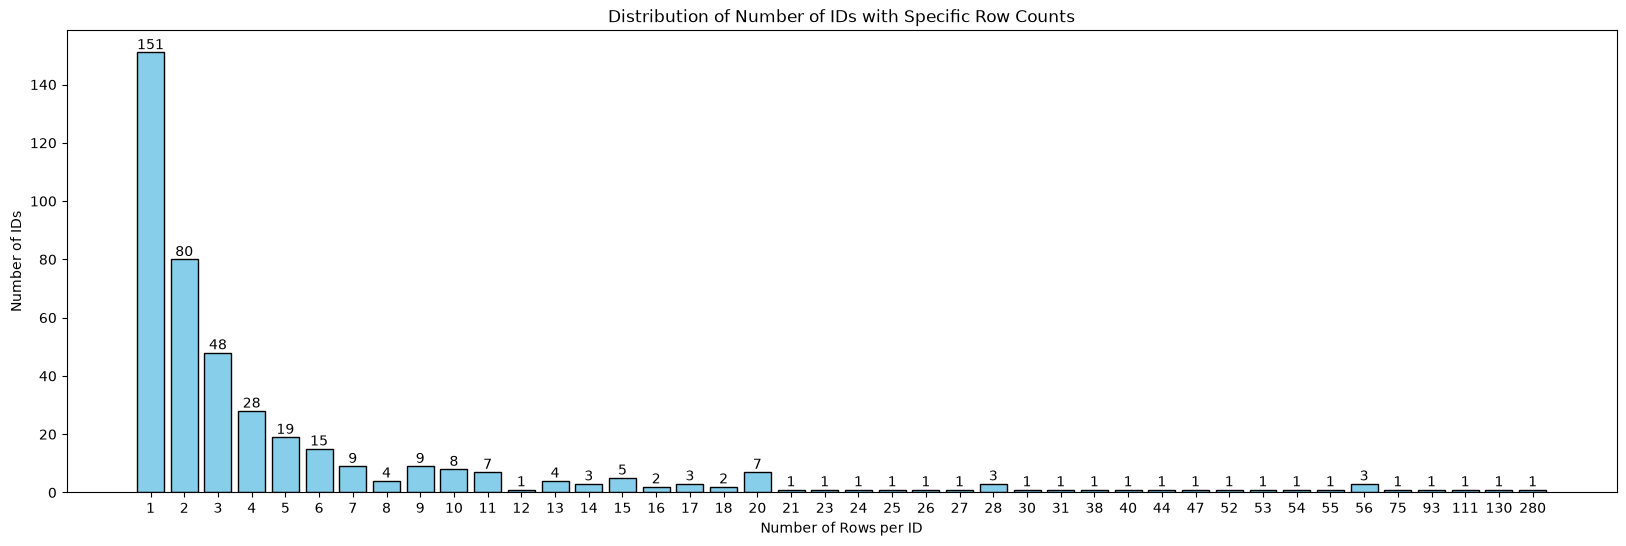

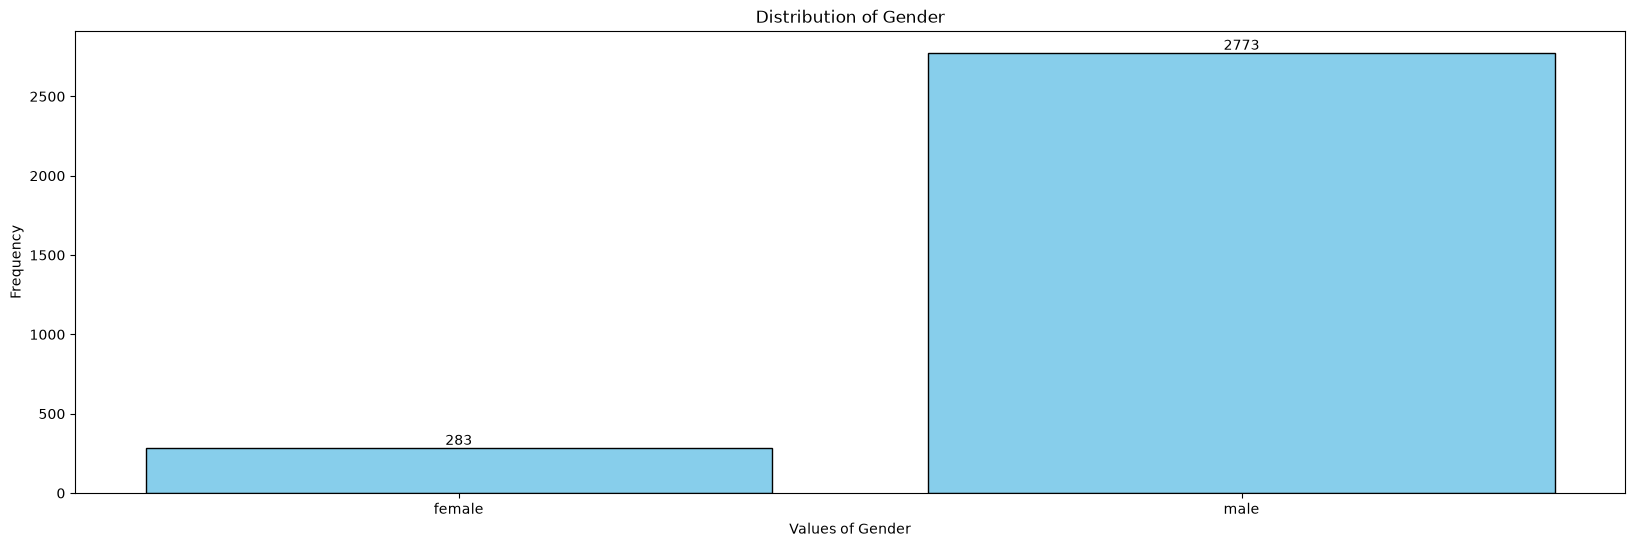

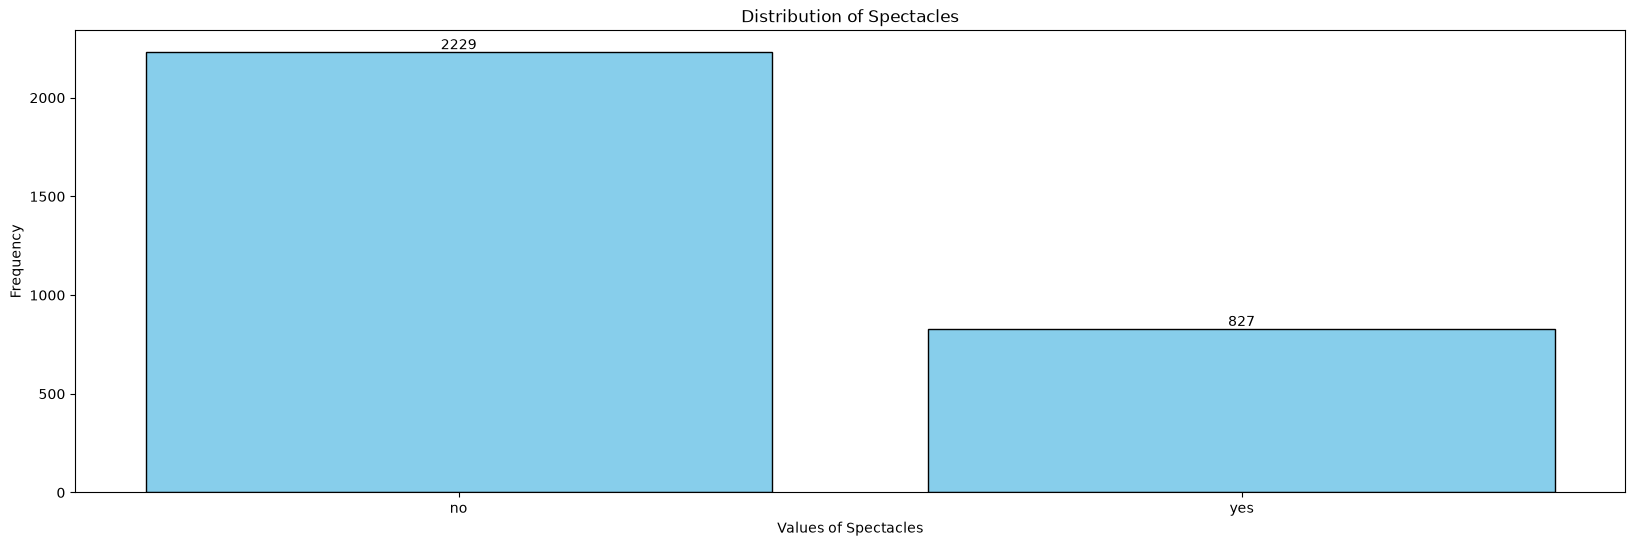

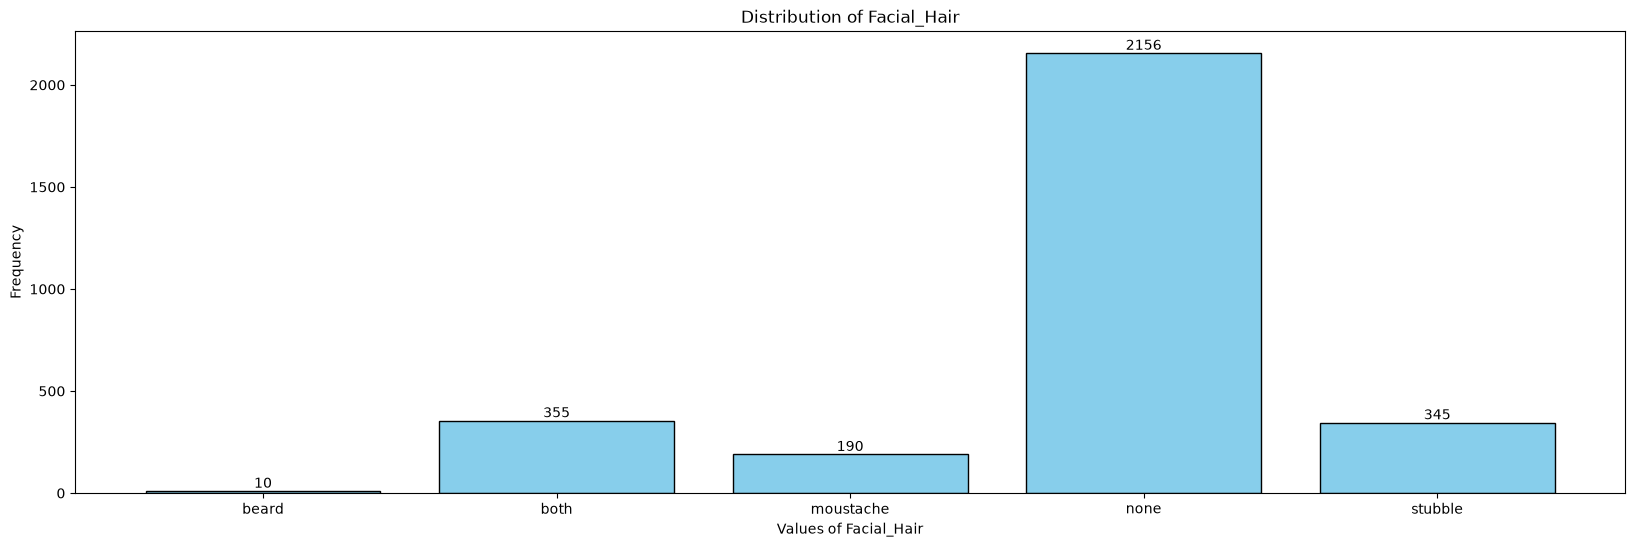

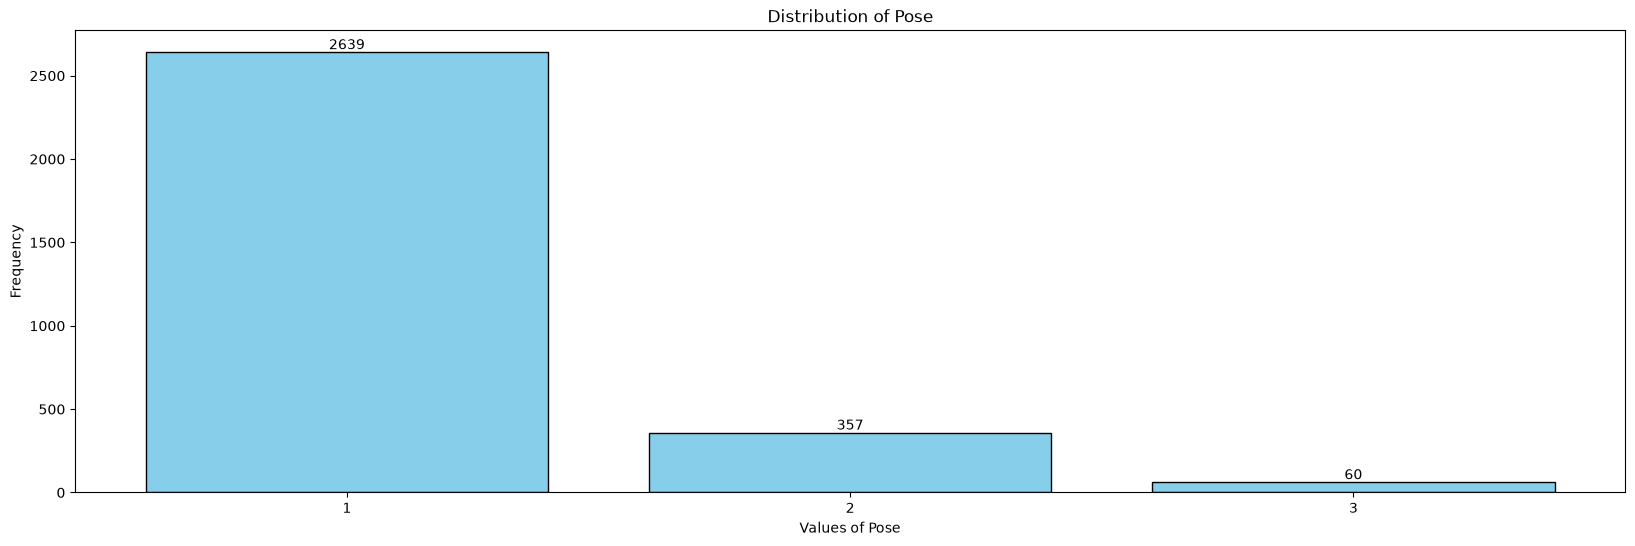

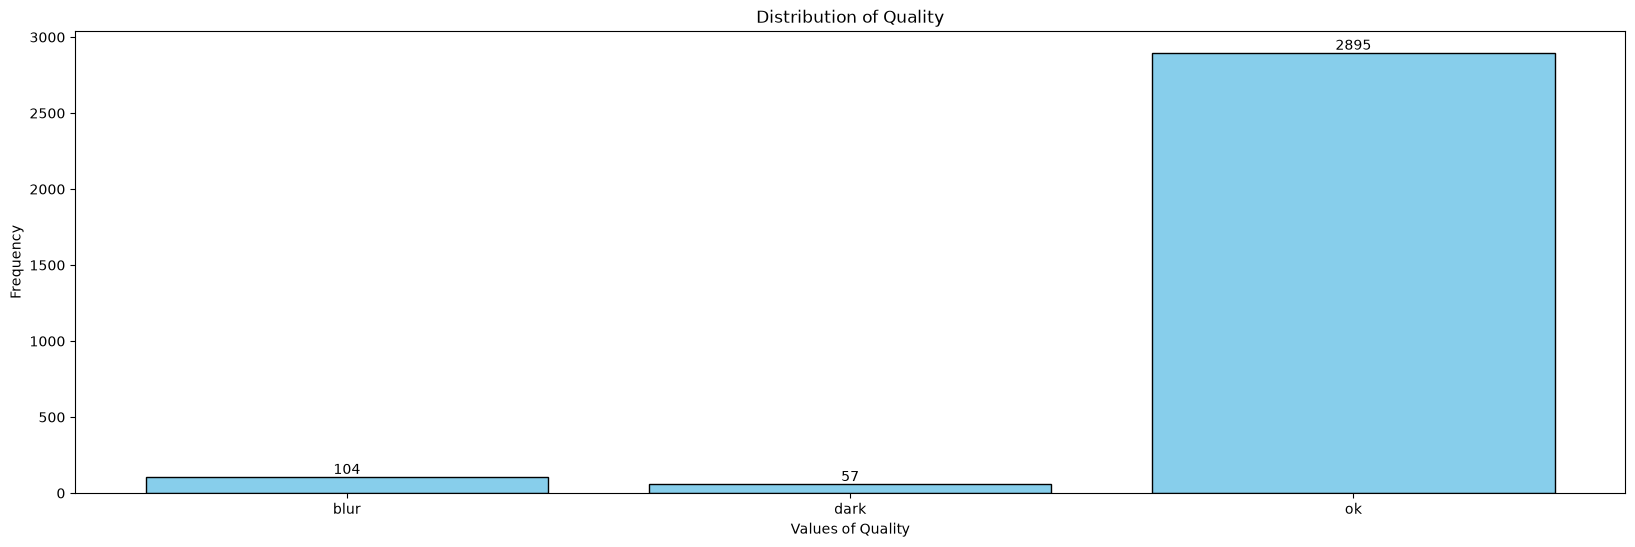

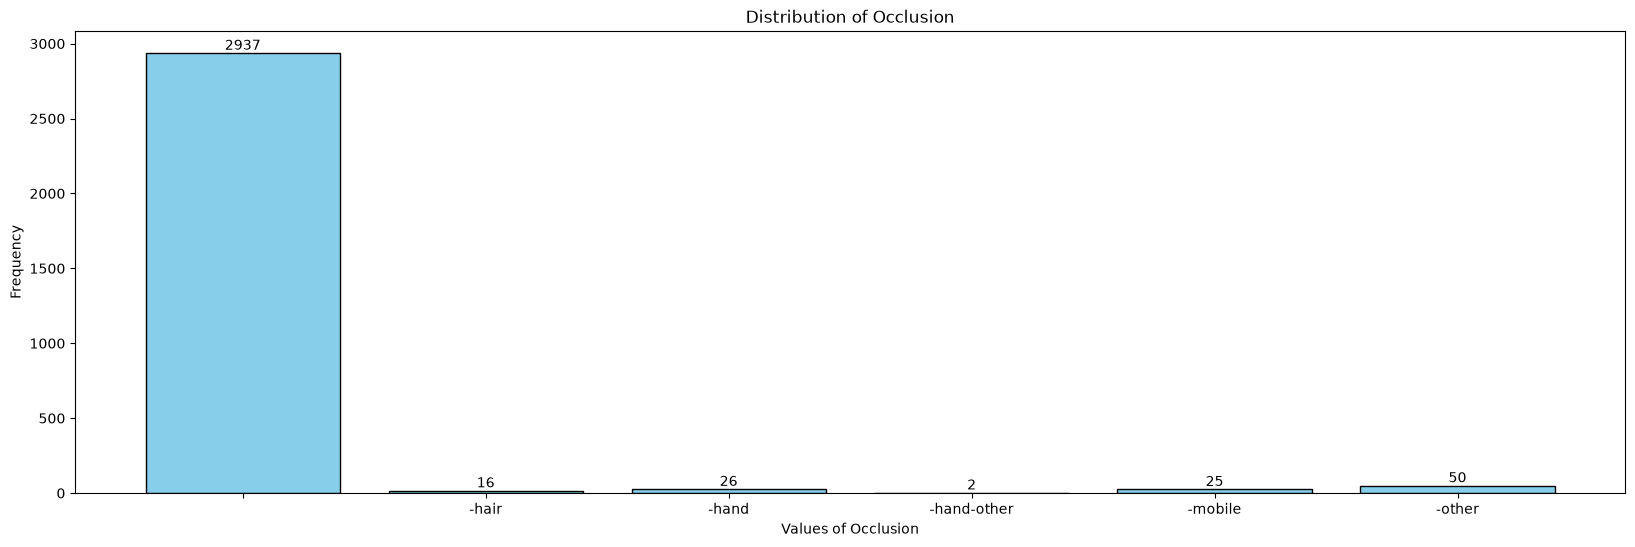

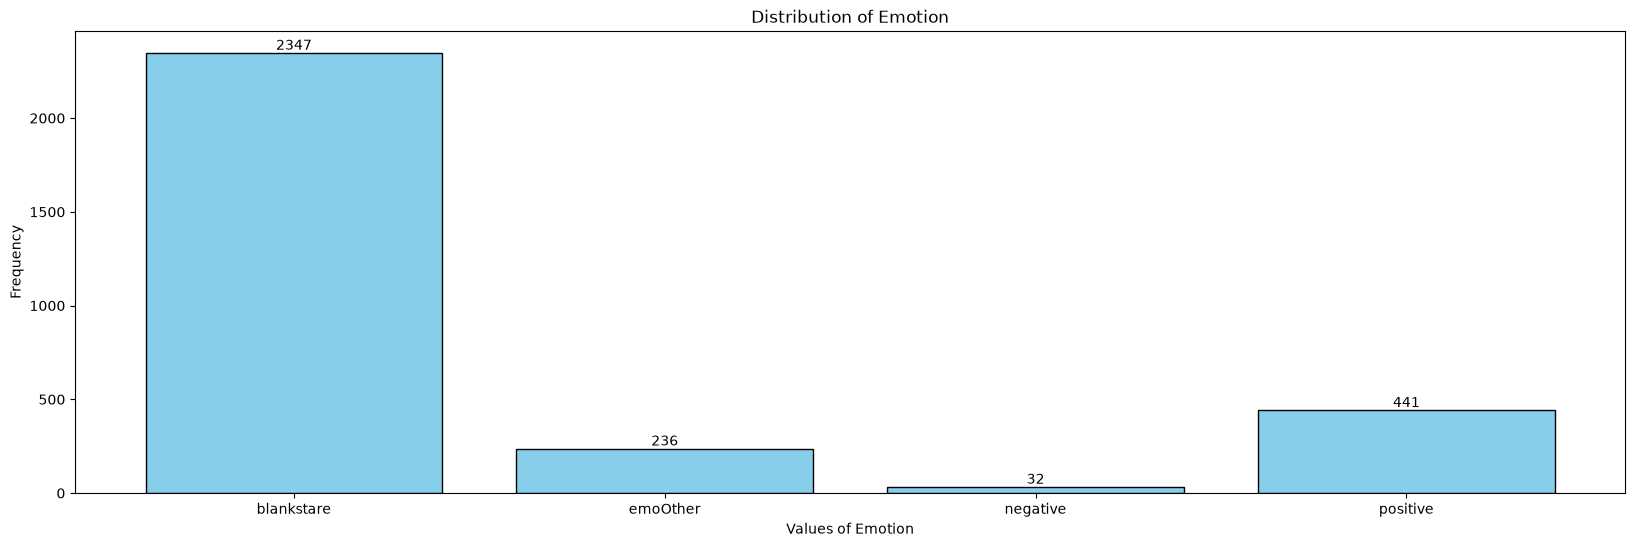

In [8]:
# Đọc file CSV và đếm số lượng row cho mỗi ID và đếm giá trị duy nhất cho từng cột (trừ 'session')
def count_data_from_csv(csv_path, headers_to_exclude):
    id_count = Counter()  # Đếm số lượng row cho mỗi id
    column_counts = {header: Counter() for header in headers_to_exclude}  # Đếm số lượng giá trị cho mỗi cột
    
    with open(csv_path, 'r') as csvfile:
        csv_reader = csv.reader(csvfile)
        headers = next(csv_reader)  # Đọc header
        
        # Đọc từng dòng và đếm
        for row in csv_reader:
            id_count[row[0]] += 1  # row[0] là ID
            
            # Đếm giá trị cho các cột cần xử lý
            for header, value in zip(headers, row):
                if header in headers_to_exclude:
                    column_counts[header][value] += 1

    return id_count, column_counts

# Vẽ biểu đồ phân bố số lượng row cho mỗi ID
def plot_row_distribution(id_count):
    row_distribution = Counter(id_count.values())

    unique_values = sorted(row_distribution.keys())
    frequency = [row_distribution[val] for val in unique_values]

    unique_values_str = list(map(str, unique_values))

    width = 0.8  # Chiều rộng cột
    fig, ax = plt.subplots(figsize=(20, 6))

    bars = ax.bar(unique_values_str, frequency, color='skyblue', edgecolor='black', width=width)

    for x, y in zip(unique_values_str, frequency):
        ax.text(x, y, str(y), ha='center', va='bottom', fontsize=10)

    ax.set_xlabel('Number of Rows per ID')
    ax.set_ylabel('Number of IDs')
    ax.set_title('Distribution of Number of IDs with Specific Row Counts')

    plt.show()

# Vẽ biểu đồ phân bố giá trị cho từng cột
def plot_column_distribution(column_counts):
    for column, count_data in column_counts.items():
        unique_values = sorted(count_data.keys())
        frequency = [count_data[val] for val in unique_values]

        unique_values_str = list(map(str, unique_values))

        width = 0.8  # Chiều rộng cột
        _, ax = plt.subplots(figsize=(20, 6))

        bars = ax.bar(unique_values_str, frequency, color='skyblue', edgecolor='black', width=width)

        for x, y in zip(unique_values_str, frequency):
            ax.text(x, y, str(y), ha='center', va='bottom', fontsize=10)

        ax.set_xlabel(f'Values of {column}')
        ax.set_ylabel('Frequency')
        ax.set_title(f'Distribution of {column}')

        plt.show()

# Đường dẫn tới file CSV
csv_path = './multi/metadata_filtered.csv'

# Các header cần xử lý (trừ 'session')
headers_to_exclude = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Quality', 'Occlusion', 'Emotion']

# Đếm số lượng row cho mỗi ID và số lượng giá trị cho các cột
id_count, column_counts = count_data_from_csv(csv_path, headers_to_exclude)

# Vẽ biểu đồ phân phối số lượng row cho mỗi ID
plot_row_distribution(id_count)

# Vẽ biểu đồ phân phối giá trị cho các cột
plot_column_distribution(column_counts)

# 2.Onehotcoding

1. Gender: ['female', 'male']

2. Spectacles(Kính): ['no', 'yes']

3. Facial_Hair(râu): ['beard'(cả hai), 'both'(cả hai), 'moustache'(ria mép), 'none'(Không có), 'stubble'(râu ria)]

4. Pose: ['1', '2', '3', '4', '5']

5. Quality(Chất lượng): ['blur' (mờ), 'dark' (tối), 'ok'(tốt)]

6. Occlusion (che phủ): ['', '-hair', '-hand', '-hand-other', '-mobile', '-other']

7. Emotion(cảm xúc): ['blankstare' (nhìn chằm chằm), 'emoOther' (), 'negative' (tiêu cực), 'positive' (tích cực)]

In [9]:
input_path = './multi/metadata_filtered.csv'
output_path = './multi/metadata_onehotcoding.csv'

df = pd.read_csv(input_path)

df.drop(columns=['Quality', 'Occlusion'], inplace=True, errors='ignore')

# Gender: female -> 0, male -> 1
df['Gender'] = df['Gender'].str.strip().map({'male': 1, 'female': 0})

# Spectacles: no -> 0, yes -> 1
df['Spectacles'] = df['Spectacles'].str.strip().map({'yes': 1, 'no': 0})

# Facial_Hair: none -> 0, tất cả còn lại -> 1
df['Facial_Hair'] = df['Facial_Hair'].astype(str).apply(lambda x: 0 if x.strip() == 'none' else 1)

# Pose: 1 -> 0, 2 -> 1, 3 -> 2
df['Pose'] = df['Pose'].map({1: 0, 2: 1, 3: 2})

# Emotion: blankstare -> 0, tất cả còn lại -> 1
df['Emotion'] = df['Emotion'].astype(str).apply(lambda x: 0 if x.strip() == 'blankstare' else 1)

# 4. Làm sạch cuối cùng
# Xóa dòng nếu có lỗi (NaN) do quá trình map
df.dropna(inplace=True)

# Chuyển về số nguyên (int) cho gọn
cols_to_int = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Emotion']
df[cols_to_int] = df[cols_to_int].astype(int)

# 5. Lưu file
print("--- Kích thước dữ liệu sau khi mã hóa:", df.shape)
print(df.head()) # In thử 5 dòng xem kết quả

df.to_csv(output_path, index=False)
print(f"\n Đã lưu file thành công tại: {output_path}")

--- Kích thước dữ liệu sau khi mã hóa: (3056, 7)
     id              session  Gender  Spectacles  Facial_Hair  Pose  Emotion
0  1001  2008-02-23_12-21-31       1           0            0     0        1
1  1001  2008-03-01_07-57-06       1           0            0     1        0
2  1001  2008-03-01_07-58-49       1           0            0     0        0
3  1001  2008-03-01_10-39-28       1           0            0     0        1
4  1001  2008-03-02_11-25-38       1           0            0     0        0

 Đã lưu file thành công tại: ./multi/metadata_onehotcoding.csv


# 3. Cập nhật 3 góc Pose vào metadata

In [10]:
df = pd.read_csv('./multi/metadata_onehotcoding.csv')

rolls, pitches, yaw_values = [], [], []

print("Đang quét và đọc file pose_6drepnet.txt cho từng session...")

for index, row in df.iterrows():
    session_id = row['id']
    session_name = row['session']
    
    session_folder = f"../Photometric_DB/{session_id}/{session_name}"
    pose_file_path = os.path.join(session_folder, "pose_6drepnet.txt")
    
    # Kiểm tra xem file pose_6drepnet.txt có tồn tại hay không
    if not os.path.exists(pose_file_path):
        raise FileNotFoundError(f"LỖI: Không tìm thấy file pose_6drepnet.txt tại thư mục: {session_folder}")
    
    # Đọc file và parse 3 giá trị Roll, Pitch, Yaw
    roll, pitch, yaw = None, None, None
    with open(pose_file_path, 'r', encoding='utf-8') as f:
        for line in f:
            line_str = line.strip()
            if line_str.startswith("Roll (deg):"):
                roll = float(line_str.split(":")[-1].strip())
            elif line_str.startswith("Pitch (deg):"):
                pitch = float(line_str.split(":")[-1].strip())
            elif line_str.startswith("Yaw (deg):"):
                yaw = float(line_str.split(":")[-1].strip())
                
    # Đảm bảo lấy đủ 3 giá trị trong file
    if roll is None or pitch is None or yaw is None:
        raise ValueError(f"LỖI: Định dạng file pose_6drepnet.txt không hợp lệ tại: {pose_file_path}")
        
    rolls.append(roll)
    pitches.append(pitch)
    yaw_values.append(yaw)

# Thêm 3 cột góc Euler vào DataFrame
df['Pose_Roll'] = rolls
df['Pose_Pitch'] = pitches
df['Pose_Yaw'] = yaw_values

# ==========================================
# 4. LƯU FILE KẾT QUẢ
# ==========================================
print("\n--- Kích thước dữ liệu sau khi cập nhật góc Pose:", df.shape)
print(df.head()) # In thử 5 dòng đầu

df.to_csv('./multi/metadata_update_pose.csv', index=False)
print("\n Đã lưu file thành công tại: metadata_update_pose.csv")

Đang quét và đọc file pose_6drepnet.txt cho từng session...

--- Kích thước dữ liệu sau khi cập nhật góc Pose: (3056, 10)
     id              session  Gender  Spectacles  Facial_Hair  Pose  Emotion  \
0  1001  2008-02-23_12-21-31       1           0            0     0        1   
1  1001  2008-03-01_07-57-06       1           0            0     1        0   
2  1001  2008-03-01_07-58-49       1           0            0     0        0   
3  1001  2008-03-01_10-39-28       1           0            0     0        1   
4  1001  2008-03-02_11-25-38       1           0            0     0        0   

   Pose_Roll  Pose_Pitch  Pose_Yaw  
0      -4.39       -2.78     -0.71  
1      -4.71       18.38      2.97  
2      -0.76        9.03     -0.58  
3      -4.51        2.01     -5.25  
4      -3.24       -1.95     -2.07  

 Đã lưu file thành công tại: metadata_update_pose.csv


# 4. Split Dataset

In [ ]:
# 1. Đọc dữ liệu
file_path = './multi/metadata_update_pose.csv'
df = pd.read_csv(file_path)

label_columns = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Emotion']

if 'id' not in df.columns:
    raise ValueError("Cột 'id' không tồn tại trong dataset!")

# Hàm tính điểm lệch phân phối nhãn so với toàn bộ dataset gốc
def calculate_distribution_divergence(train_df, val_df, test_df, full_df, columns):
    divergence = 0.0
    for col in columns:
        full_dist = full_df[col].value_counts(normalize=True).to_dict()
        train_dist = train_df[col].value_counts(normalize=True).to_dict()
        val_dist = val_df[col].value_counts(normalize=True).to_dict()
        test_dist = test_df[col].value_counts(normalize=True).to_dict()
        
        # Cộng tổng sai số tuyệt đối so với phân phối gốc
        for k, p in full_dist.items():
            divergence += abs(train_dist.get(k, 0) - p)
            divergence += abs(val_dist.get(k, 0) - p)
            divergence += abs(test_dist.get(k, 0) - p)
            
    return divergence # Điểm càng nhỏ nghĩa là càng cân bằng giống tập gốc

best_score = float('inf')
best_splits = None
best_seed = None

num_seeds_to_try = 1000
print(f"Đang quét qua {num_seeds_to_try} seeds để tìm bộ chia tối ưu nhất...")

# 2. Vòng lặp tìm kiếm seed tối ưu
for seed in range(num_seeds_to_try):
    # Bước 2.1: Tách Train (~70%) và phần còn lại (~30%) dựa theo ID
    gss1 = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=seed)
    try:
        train_idx, val_test_idx = next(gss1.split(df, groups=df['id']))
    except StopIteration:
        continue
        
    train_set = df.iloc[train_idx]
    val_test_df = df.iloc[val_test_idx].reset_index(drop=True)
    
    # Bước 2.2: Tách phần còn lại thành Validate (~15%) và Test (~15%) dựa theo ID
    gss2 = GroupShuffleSplit(n_splits=1, train_size=0.5, random_state=seed + 999)
    try:
        val_sub_idx, test_sub_idx = next(gss2.split(val_test_df, groups=val_test_df['id']))
    except StopIteration:
        continue
        
    val_idx = val_test_idx[val_sub_idx]
    test_idx = val_test_idx[test_sub_idx]
    
    val_set = df.iloc[val_idx]
    test_set = df.iloc[test_idx]
    
    # 3. Kiểm tra ràng buộc nghiêm ngặt: Tuyệt đối không trùng ID giữa các tập
    t_ids = set(train_set['id'])
    v_ids = set(val_set['id'])
    te_ids = set(test_set['id'])
    
    if t_ids.intersection(v_ids) or t_ids.intersection(te_ids) or v_ids.intersection(te_ids):
        continue # Bỏ qua nếu có ID bị lọt qua lại giữa các tập
        
    # 4. Tính điểm cân bằng nhãn
    score = calculate_distribution_divergence(train_set, val_set, test_set, df, label_columns)
    
    # Cập nhật nếu tìm thấy seed tốt hơn (điểm lệch thấp nhất)
    if score < best_score:
        best_score = score
        best_splits = (train_set, val_set, test_set)
        best_seed = seed

# 5. Xuất kết quả tốt nhất tìm được
if best_splits is not None:
    train_set, val_set, test_set = best_splits
    print(f"\nĐã tìm thấy! Best Seed: {best_seed} (Điểm lệch thấp nhất: {best_score:.4f})")
    
    print(f"\n--- Quy mô các tập ---")
    print(f"Train size: {len(train_set)} dòng ({len(set(train_set['id']))} IDs)")
    print(f"Validate size: {len(val_set)} dòng ({len(set(val_set['id']))} IDs)")
    print(f"Test size: {len(test_set)} dòng ({len(set(test_set['id']))} IDs)")
    
    # Kiểm tra lại độ trùng lặp ID lần cuối
    t_ids, v_ids, te_ids = set(train_set['id']), set(val_set['id']), set(test_set['id'])
    print(f"\n--- Kiểm tra Data Leakage ID ---")
    print(f"Trùng Train & Val: {len(t_ids.intersection(v_ids))}")
    print(f"Trùng Train & Test: {len(t_ids.intersection(te_ids))}")
    print(f"Trùng Val & Test: {len(v_ids.intersection(te_ids))}")
    
    # Lưu ra file CSV
    train_set.sort_values(by='id').to_csv('./multi/train_set.csv', index=False)
    val_set.sort_values(by='id').to_csv('./multi/val_set.csv', index=False)
    test_set.sort_values(by='id').to_csv('./multi/test_set.csv', index=False)
    print("\nĐã lưu các tập dữ liệu sạch ra file thành công!")
else:
    print("Không tìm thấy cấu hình phù hợp, hãy thử tăng số lượng seeds quét lên.")

Đang quét qua 1000 seeds để tìm bộ chia tối ưu nhất...

Đã tìm thấy! Best Seed: 815 (Điểm lệch thấp nhất: 0.5093)

--- Quy mô các tập ---
Train size: 2292 dòng (302 IDs)
Validate size: 312 dòng (65 IDs)
Test size: 452 dòng (65 IDs)

--- Kiểm tra Data Leakage ID ---
Trùng Train & Val: 0
Trùng Train & Test: 0
Trùng Val & Test: 0

Đã lưu các tập dữ liệu sạch ra file thành công!


In [12]:
# Đọc lại các file đã lưu để kiểm tra
train_set = pd.read_csv('./multi/train_set.csv')
val_set = pd.read_csv('./multi/val_set.csv')
test_set = pd.read_csv('./multi/test_set.csv')
full_df = pd.read_csv('./multi/metadata_onehotcoding.csv')

label_columns = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Emotion']

# Hàm in bảng so sánh tỷ lệ phần trăm (%)
def print_comparison_table(full_df, train_df, val_df, test_df, columns):
    for col in columns:
        print(f"\n==============================")
        print(f"📌 BẢNG SO SÁNH PHÂN PHỐI: {col}")
        print(f"==============================")
        
        # Tính tỷ lệ % và gộp thành một bảng DataFrame
        summary_df = pd.DataFrame({
            'Full (%)': full_df[col].value_counts(normalize=True) * 100,
            'Train (%)': train_df[col].value_counts(normalize=True) * 100,
            'Validate (%)': val_df[col].value_counts(normalize=True) * 100,
            'Test (%)': test_df[col].value_counts(normalize=True) * 100
        }).fillna(0)
        
        # Làm tròn 2 chữ số thập phân cho dễ nhìn
        print(summary_df.round(2))

# Thực thi hàm in
print_comparison_table(full_df, train_set, val_set, test_set, label_columns)


📌 BẢNG SO SÁNH PHÂN PHỐI: Gender
        Full (%)  Train (%)  Validate (%)  Test (%)
Gender                                             
1          90.74      90.62         90.38     91.59
0           9.26       9.38          9.62      8.41

📌 BẢNG SO SÁNH PHÂN PHỐI: Spectacles
            Full (%)  Train (%)  Validate (%)  Test (%)
Spectacles                                             
0              72.94       72.6         71.15     75.88
1              27.06       27.4         28.85     24.12

📌 BẢNG SO SÁNH PHÂN PHỐI: Facial_Hair
             Full (%)  Train (%)  Validate (%)  Test (%)
Facial_Hair                                             
0               70.55      69.02         69.87     78.76
1               29.45      30.98         30.13     21.24

📌 BẢNG SO SÁNH PHÂN PHỐI: Pose
      Full (%)  Train (%)  Validate (%)  Test (%)
Pose                                             
0        86.35      86.74         87.18     83.85
1        11.68      11.30          9.94     14.

Chia tập test thành 2 tập gallery set và probe set

In [13]:
# 1. Đọc file CSV gốc
test_set = pd.read_csv("./multi/test_set.csv")

# 2. Lấy ngẫu nhiên đúng 1 mẫu cho mỗi 'id' (giữ nguyên index gốc)
gallery_sample = test_set.groupby('id', as_index=False).sample(n=1, random_state=42)

# 3. Drop các index đã chọn để lấy các mẫu còn lại cho Probe
gallery_remaining = test_set.drop(gallery_sample.index)

# 4. Lưu ra 2 file CSV
gallery_sample.to_csv("./multi/gallery_set.csv", index=True)
gallery_remaining.to_csv("./multi/probe_set.csv", index=True)

In [14]:
# 1. Đọc lại output từ 2 file CSV đã lưu
gallery_saved = pd.read_csv("./multi/gallery_set.csv")
probe_saved = pd.read_csv("./multi/probe_set.csv")
df_original = pd.read_csv("./multi/test_set.csv")

print("=== 1. THỐNG KÊ SỐ LƯỢNG MẪU ===")
print(f"Tổng số dòng ban đầu: {len(df_original)}")
print(f"Số dòng trong gallery_set.csv: {len(gallery_saved)}")
print(f"Số dòng trong probe_set.csv: {len(probe_saved)}")
print(f"Tổng 2 file output: {len(gallery_saved) + len(probe_saved)}")

# 2. Tạo tập các cặp (id, session) duy nhất để đối sánh
gallery_pairs = set(zip(gallery_saved['id'], gallery_saved['session']))
probe_pairs = set(zip(probe_saved['id'], probe_saved['session']))

# 3. Kiểm tra các mẫu trùng lặp (Overlap) xuất hiện ở cả 2 file
overlap_pairs = gallery_pairs.intersection(probe_pairs)

print("\n=== 2. KẾT QUẢ ĐỐI SÁNH (CHECK OVERLAP) ===")
if len(overlap_pairs) > 0:
    print(f"❌ CẢNH BÁO: Phát hiện {len(overlap_pairs)} mẫu (id, session) BỊ TRÙNG xuất hiện ở CẢ HAI FILE!")
    print("\nVí dụ 5 mẫu bị trùng lặp:")
    for pair in list(overlap_pairs)[:5]:
        print(f"   - ID: {pair[0]}, Session: {pair[1]}")
else:
    print("✅ Không có mẫu nào bị trùng giữa 2 file.")

# 4. Kiểm tra số lượng mẫu bị mất/thừa so với file gốc
original_pairs = set(zip(df_original['id'], df_original['session']))
combined_output_pairs = gallery_pairs.union(probe_pairs)

missing_pairs = original_pairs - combined_output_pairs
if len(missing_pairs) > 0:
    print(f"\n❌ Phát hiện {len(missing_pairs)} mẫu từ file gốc BỊ MẤT (không nằm trong file nào cả).")
    print("Ví dụ 5 mẫu bị mất:")
    for pair in list(missing_pairs)[:5]:
        print(f"   - ID: {pair[0]}, Session: {pair[1]}")

=== 1. THỐNG KÊ SỐ LƯỢNG MẪU ===
Tổng số dòng ban đầu: 452
Số dòng trong gallery_set.csv: 65
Số dòng trong probe_set.csv: 387
Tổng 2 file output: 452

=== 2. KẾT QUẢ ĐỐI SÁNH (CHECK OVERLAP) ===
✅ Không có mẫu nào bị trùng giữa 2 file.


# 5. Phân tích dataset sau chia

In [9]:
# Đọc file CSV và đếm số lượng các loại giá trị duy nhất cho các cột trừ 'id' và 'session'
def count_unique_values(csv_path, headers_to_exclude):
    unique_values_by_column = {header: set() for header in headers_to_exclude}

    with open(csv_path, 'r') as csvfile:
        csv_reader = csv.reader(csvfile)
        headers = next(csv_reader)  # Đọc header
        
        # Lấy chỉ số của các header cần đếm
        for row in csv_reader:
            for header, value in zip(headers, row):
                if header in headers_to_exclude:
                    unique_values_by_column[header].add(value)  # Thêm giá trị duy nhất vào set

    return unique_values_by_column

# Hiển thị số lượng các loại (unique values) có trong từng cột
def display_unique_values(unique_values_by_column):
    for column, unique_values in unique_values_by_column.items():
        print(f"Unique values in {column}: {sorted(unique_values)}")
        print(f"Total number of unique values in {column}: {len(unique_values)}\n")

# Đường dẫn tới file CSV
csv_path = './multi/train_set.csv'

# Các header cần xử lý (trừ 'id' và 'session')
headers_to_exclude = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Emotion']

# Đếm các loại giá trị duy nhất trong từng cột
unique_values_by_column = count_unique_values(csv_path, headers_to_exclude)

# Hiển thị các loại và số lượng có trong từng cột
display_unique_values(unique_values_by_column)

Unique values in Gender: ['0', '1']
Total number of unique values in Gender: 2

Unique values in Spectacles: ['0', '1']
Total number of unique values in Spectacles: 2

Unique values in Facial_Hair: ['0', '1']
Total number of unique values in Facial_Hair: 2

Unique values in Pose: ['0', '1', '2']
Total number of unique values in Pose: 3

Unique values in Emotion: ['0', '1']
Total number of unique values in Emotion: 2



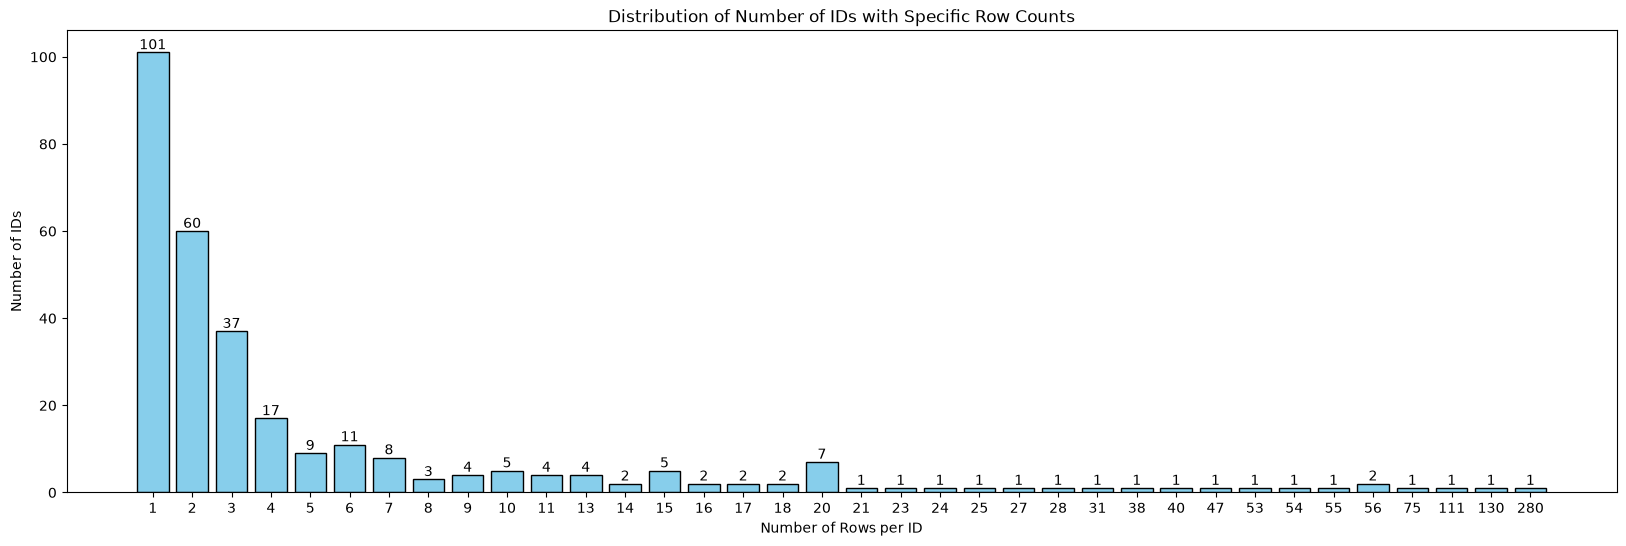

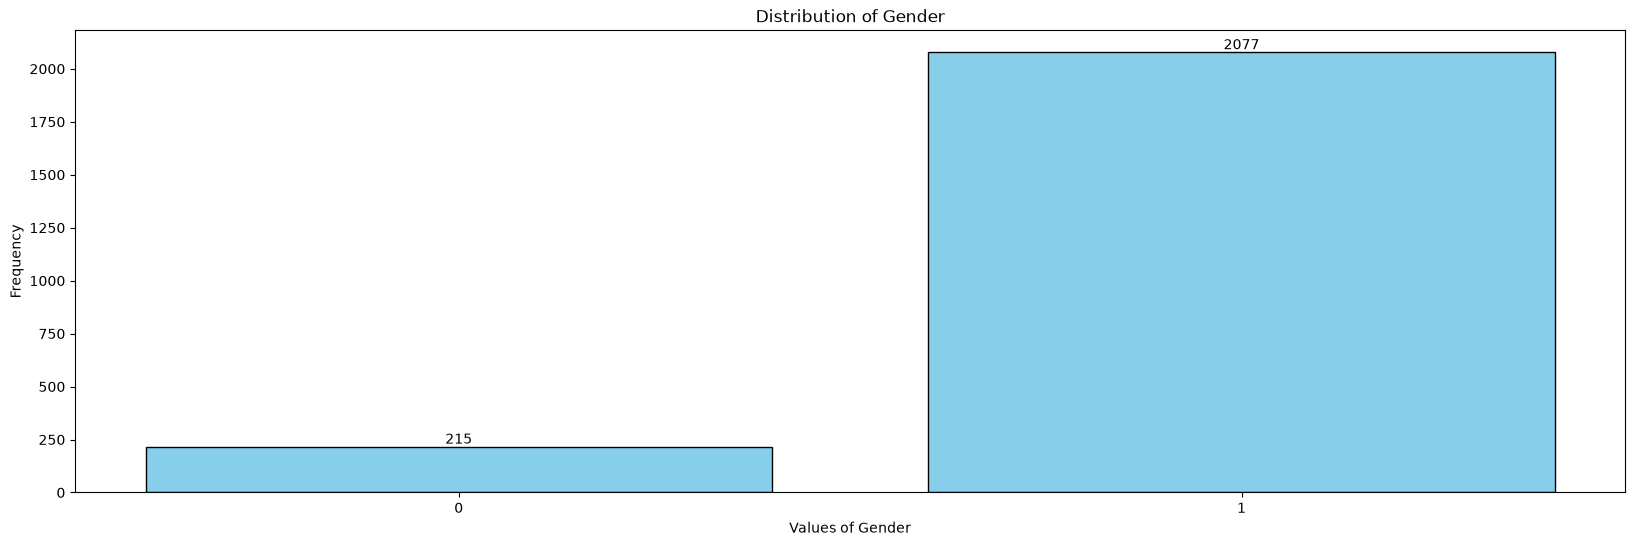

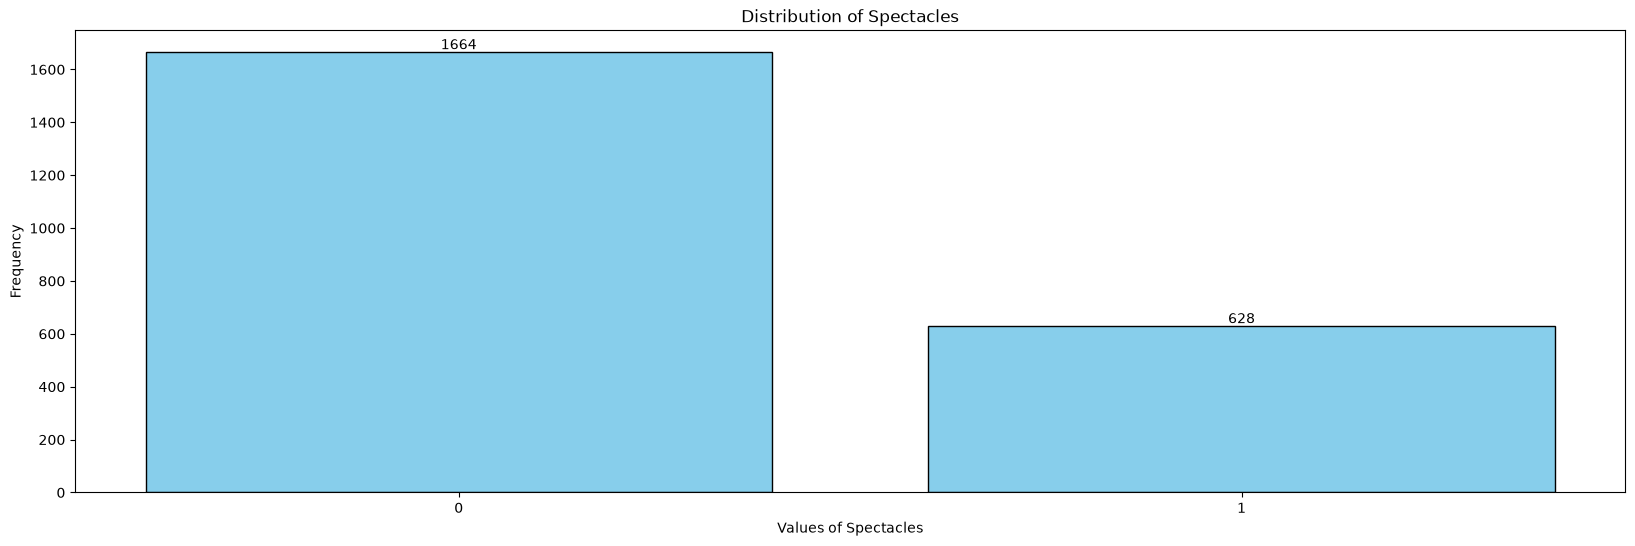

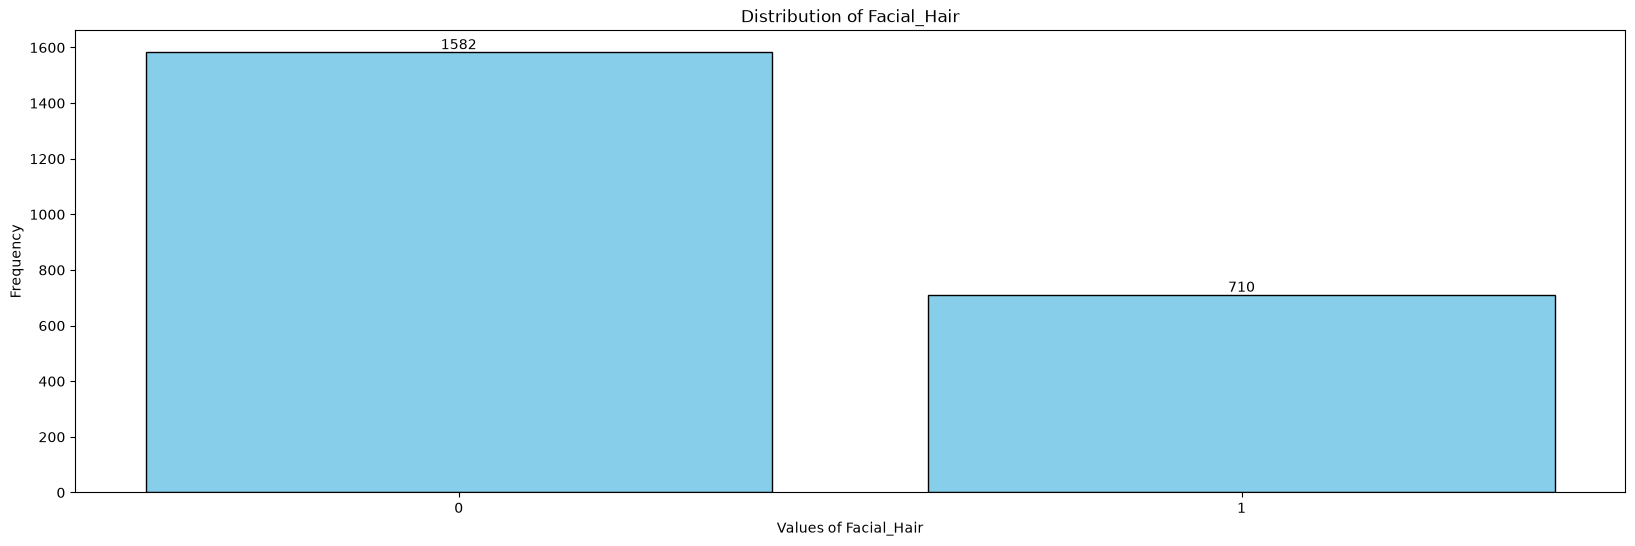

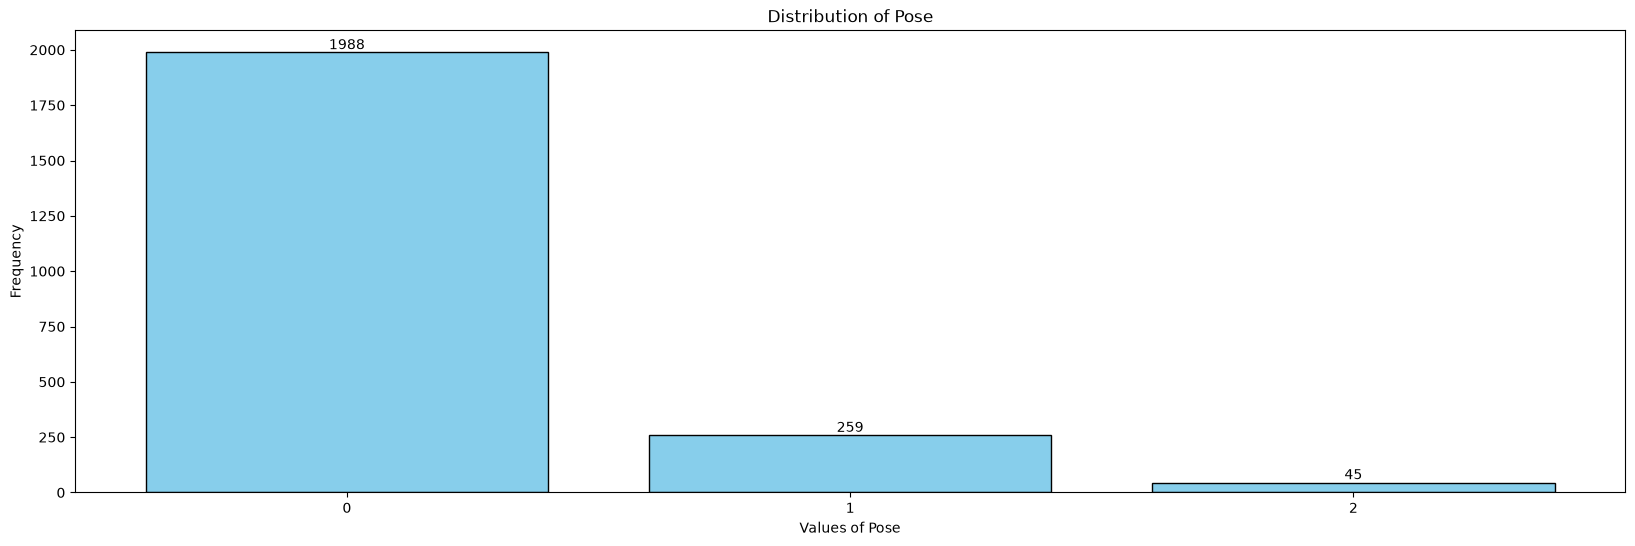

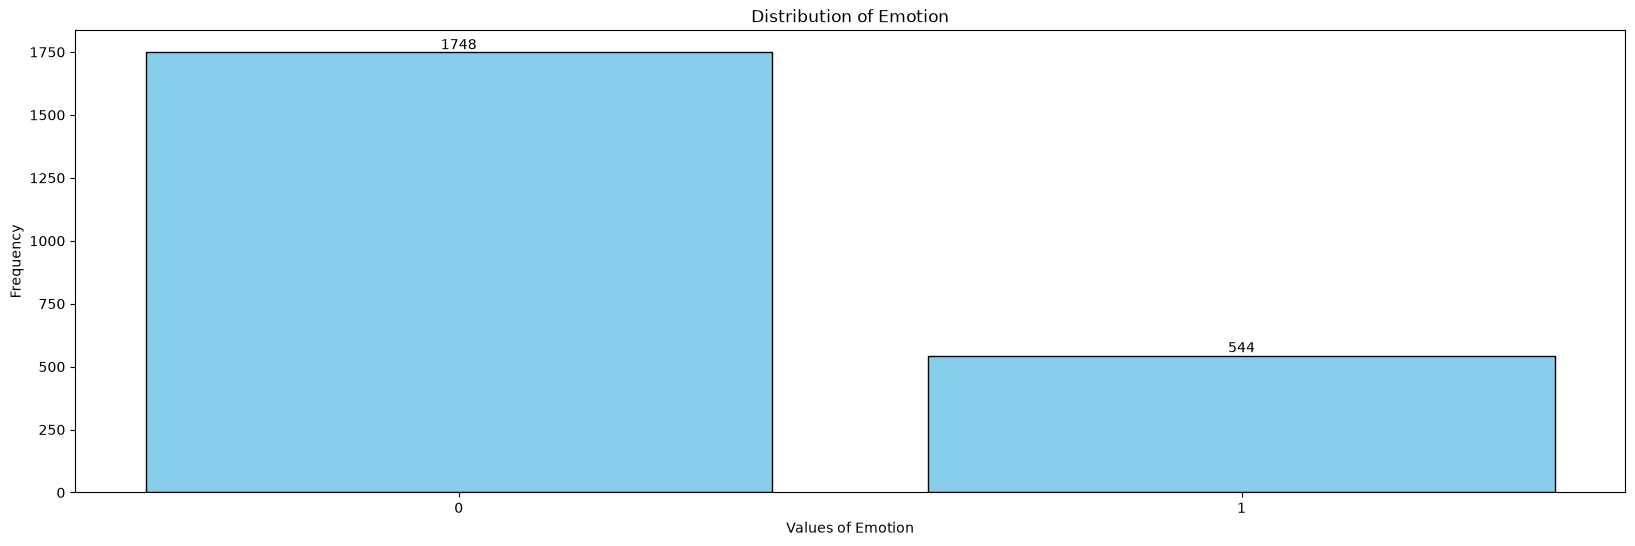

In [10]:
# Đọc file CSV và đếm số lượng row cho mỗi ID và đếm giá trị duy nhất cho từng cột (trừ 'session')
def count_data_from_csv(csv_path, headers_to_exclude):
    id_count = Counter()  # Đếm số lượng row cho mỗi id
    column_counts = {header: Counter() for header in headers_to_exclude}  # Đếm số lượng giá trị cho mỗi cột
    
    with open(csv_path, 'r') as csvfile:
        csv_reader = csv.reader(csvfile)
        headers = next(csv_reader)  # Đọc header
        
        # Đọc từng dòng và đếm
        for row in csv_reader:
            id_count[row[0]] += 1  # row[0] là ID
            
            # Đếm giá trị cho các cột cần xử lý
            for header, value in zip(headers, row):
                if header in headers_to_exclude:
                    column_counts[header][value] += 1

    return id_count, column_counts

# Vẽ biểu đồ phân bố số lượng row cho mỗi ID
def plot_row_distribution(id_count):
    row_distribution = Counter(id_count.values())

    unique_values = sorted(row_distribution.keys())
    frequency = [row_distribution[val] for val in unique_values]

    unique_values_str = list(map(str, unique_values))

    width = 0.8  # Chiều rộng cột
    fig, ax = plt.subplots(figsize=(20, 6))

    bars = ax.bar(unique_values_str, frequency, color='skyblue', edgecolor='black', width=width)

    for x, y in zip(unique_values_str, frequency):
        ax.text(x, y, str(y), ha='center', va='bottom', fontsize=10)

    ax.set_xlabel('Number of Rows per ID')
    ax.set_ylabel('Number of IDs')
    ax.set_title('Distribution of Number of IDs with Specific Row Counts')

    plt.show()

# Vẽ biểu đồ phân bố giá trị cho từng cột
def plot_column_distribution(column_counts):
    for column, count_data in column_counts.items():
        unique_values = sorted(count_data.keys())
        frequency = [count_data[val] for val in unique_values]

        unique_values_str = list(map(str, unique_values))

        width = 0.8  # Chiều rộng cột
        _, ax = plt.subplots(figsize=(20, 6))

        bars = ax.bar(unique_values_str, frequency, color='skyblue', edgecolor='black', width=width)

        for x, y in zip(unique_values_str, frequency):
            ax.text(x, y, str(y), ha='center', va='bottom', fontsize=10)

        ax.set_xlabel(f'Values of {column}')
        ax.set_ylabel('Frequency')
        ax.set_title(f'Distribution of {column}')

        plt.show()

# Đường dẫn tới file CSV
csv_path = './multi/train_set.csv'

# Các header cần xử lý (trừ 'session')
headers_to_exclude = ['Gender', 'Spectacles', 'Facial_Hair', 'Pose', 'Emotion']

# Đếm số lượng row cho mỗi ID và số lượng giá trị cho các cột
id_count, column_counts = count_data_from_csv(csv_path, headers_to_exclude)

# Vẽ biểu đồ phân phối số lượng row cho mỗi ID
plot_row_distribution(id_count)

# Vẽ biểu đồ phân phối giá trị cho các cột
plot_column_distribution(column_counts)